In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df_socr = pd.read_excel('/content/drive/MyDrive/ML 2026/Praktikum03/data/socr.xlsx')
df_socr.head()

,Index,Height(Inches),Weight(Pounds)
0,1,65.78331,112.9925
1,2,71.51521,136.4873
2,3,69.39874,153.0269
3,4,68.21660,142.3354
4,5,67.78781,144.2971


In [ ]:
# Mencari informasi umum pada data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Jenis Kelamin      100000 non-null  object 
 1   Umur (bulan)       100000 non-null  int64  
 2   Tinggi Badan (cm)  100000 non-null  float64
 3   Berat Badan (kg)   100000 non-null  float64
 4   Stunting           100000 non-null  object 
 5   Wasting            100000 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 4.6+ MB


In [ ]:
df_socr.describe()

,Index,Height(Inches),Weight(Pounds)
count,25000.000000,25000.000000,25000.000000
mean,12500.500000,67.993114,127.079421
std,7217.022701,1.901679,11.660898
min,1.000000,60.278360,78.014760
25%,6250.750000,66.704397,119.308675
50%,12500.500000,67.995700,127.157750
75%,18750.250000,69.272958,134.892850
max,25000.000000,75.152800,170.924000


In [ ]:
df_socr = (
df_socr[["Height(Inches)", "Weight(Pounds)"]].rename(columns={
   "Height(Inches)": "tinggi_cm",
    "Weight(Pounds)": "berat_kg"}).assign(
        tinggi_cm=lambda d: d["tinggi_cm"] * 2.54, # in -> cm
        berat_kg=lambda d: d["berat_kg"] * 0.45359237 # lb -> kg
    )
    .round({"tinggi_cm": 2, "berat_kg": 2}).copy()
    )

df_socr.head()

,tinggi_cm,berat_kg
0,167.09,51.25
1,181.65,61.91
2,176.27,69.41
3,173.27,64.56
4,172.18,65.45


In [ ]:
from sklearn.model_selection import train_test_split
X = df_socr[["tinggi_cm"]]
y = df_socr["berat_kg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

print("Koefisien (kg per cm):", model.coef_[0])
print("Intersep (kg):        ", model.intercept_)
print("R2 (test):            ", r2)
print("MAE (kg):             ", mean_absolute_error(y_test, y_pred))
mse =mean_squared_error(y_test, y_pred) #default squared=True
rmse = np.sqrt(mse)
print("RMSE (kg):            ", rmse)

Koefisien (kg per cm): 0.5484528537924076
Intersep (kg):         -37.07361066572892
R2 (test):             0.2605732097944444
MAE (kg):              3.644517249731769
RMSE (kg):             4.59205924760664


In [ ]:
slope = model.coef_[0]
intercept = model.intercept_
print(f"Persamaan: y = {slope:.3f} * x + {intercept:.3f}")


Persamaan: y = 0.548 * x + -37.074


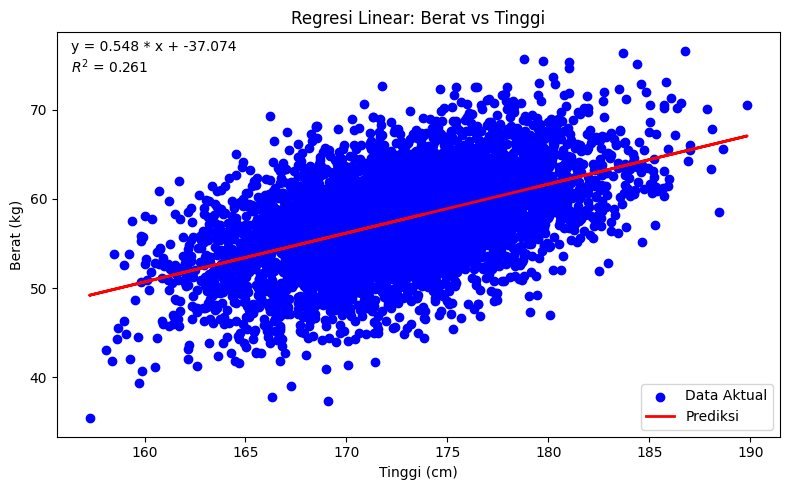

In [ ]:
import matplotlib.pyplot as plt

# Plot data scatter
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="blue", label="Data Aktual")

# Garis regresi
plt.plot(X_test, y_pred, color="red", linewidth=2, label="Prediksi")
plt.xlabel("Tinggi (cm)")
plt.ylabel("Berat (kg)")
plt.title("Regresi Linear: Berat vs Tinggi")
plt.text(
    0.02, 0.98,
    f"y = {slope:.3f} * x + {intercept:.3f}\n$R^2$ = {r2:.3f}",
    transform=plt.gca().transAxes, va="top"
)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
y_pred_test = model.predict(X_test)

# Buat tabel hasil (tinggi, aktual, prediksi, dan error)
hasil = pd.DataFrame({
    "Tinggi (cm)": X_test["tinggi_cm"].to_numpy(),
    "Berat aktual (kg)": y_test.to_numpy(),
    "Berat Prediksi (kg)": y_pred_test,
})

# 1) Selisih error (positif = overpredict)
hasil["Selisih error (kg)"] = hasil["Berat Prediksi (kg)"] - hasil["Berat aktual (kg)"]

# 2) Akurasi per-baris (100 * (1 - |error/aktual|)), dibatasi 0-100
denom = hasil["Berat aktual (kg)"].replace(0, np.nan) # antisipasi pembagi nol
hasil["Akurasi (%)"] = (1 - (hasil["Selisih error (kg)"].abs() / denom)).clip(lower=0, upper=1) * 100

hasil

,Tinggi (cm),Berat aktual (kg),Berat Prediksi (kg),Selisih error (kg),Akurasi (%)
0,173.80,60.91,58.247495,-2.662505,95.628789
1,172.46,50.79,57.512568,6.722568,86.763992
2,171.85,61.68,57.178012,-4.501988,92.701057
3,175.29,57.33,59.064690,1.734690,96.974202
4,175.29,45.44,59.064690,13.624690,70.016087
...,...,...,...,...,...
4995,175.10,62.64,58.960484,-3.679516,94.125932
4996,170.90,47.72,56.656982,8.936982,81.272041
4997,174.17,64.04,58.450423,-5.589577,91.271741
4998,170.42,58.75,56.393725,-2.356275,95.989319


In [ ]:
import pandas as pd

# Read the CSV file with a comma delimeter
df = pd.read_excel('/content/drive/MyDrive/ML 2026/Praktikum03/data/stunting_wasting_dataset.xlsx')

# cetak header data (5 baris data) dari file
df.head()

,Jenis Kelamin,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting,Wasting
0,Laki-laki,19,91.6,13.3,Tall,Risk of Overweight
1,Laki-laki,20,77.7,8.5,Stunted,Underweight
2,Laki-laki,10,79.0,10.3,Normal,Risk of Overweight
3,Perempuan,2,50.3,8.3,Severely Stunted,Risk of Overweight
4,Perempuan,5,56.4,10.9,Severely Stunted,Risk of Overweight


In [ ]:
df.describe()

,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg)
count,100000.000000,100000.000000,100000.000000
mean,11.992580,73.132657,9.259256
std,7.199671,11.360846,3.300780
min,0.000000,42.600000,1.000000
25%,6.000000,65.500000,6.900000
50%,12.000000,74.200000,9.200000
75%,18.000000,81.400000,11.700000
max,24.000000,97.600000,17.200000


In [ ]:
df_socr = (df[["Berat Badan (kg)", "Jenis Kelamin", "Umur (bulan)", "Tinggi Badan (cm)"]]
        .rename(columns={"Jenis Kelamin": "jk", "Umur (bulan)": "umur_bln",
                         "Tinggi Badan (cm)": "tinggi_cm", "Berat Badan (kg)": "berat_kg"})
)

## Laki-Laki: 1, Perempuan: 0
df_socr["jk"] = df_socr["jk"].map({"Laki-laki": 1, "Perempuan": 0})
df_socr.head()

,berat_kg,jk,umur_bln,tinggi_cm
0,13.3,1,19,91.6
1,8.5,1,20,77.7
2,10.3,1,10,79.0
3,8.3,0,2,50.3
4,10.9,0,5,56.4


In [ ]:
#Hitung matriks korelasi
corr_matrix = df_socr.corr()

print(corr_matrix)



           berat_kg        jk  umur_bln  tinggi_cm
berat_kg   1.000000  0.045797  0.665389   0.626005
jk         0.045797  1.000000  0.004046   0.073505
umur_bln   0.665389  0.004046  1.000000   0.875869
tinggi_cm  0.626005  0.073505  0.875869   1.000000


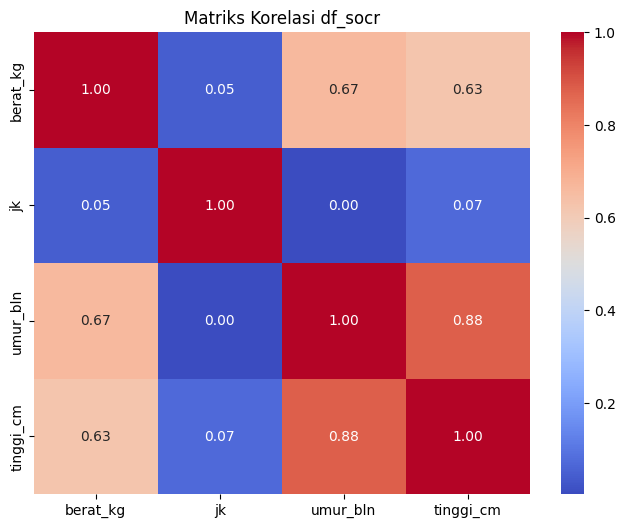

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriks Korelasi df_socr")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Misalkan target (Y) adalah berat badan, # Variabel dependen
y = df_socr["berat_kg"]

# Fitur (X) adalah umur dan tinggi, # Variabel independen
X = df_socr[["umur_bln", "tinggi_cm"]]

# Bagi data 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42 # random_state supaya hasil konsisten
)

## Cetak Pembagian Data
print("Jumlah data train :", len(X_train))
print("Jumlah data test  :", len(X_test))

## cek apakah sudah ada konstanta pada data training
X_train.head()

Jumlah data train : 80000
Jumlah data test  : 20000


,umur_bln,tinggi_cm
75220,2,51.9
48955,13,74.3
44966,17,86.7
13568,16,76.8
92727,20,78.5


In [ ]:
## Tambahkan konstanta
X_train_const = sm.add_constant(X_train)
X_train_const.head()

,const,umur_bln,tinggi_cm
75220,1.0,2,51.9
48955,1.0,13,74.3
44966,1.0,17,86.7
13568,1.0,16,76.8
92727,1.0,20,78.5


In [ ]:
import statsmodels.api as sm

# Buat model OLS
model = sm.OLS(y_train, X_train_const).fit()
print('-----------------------------')
print(model.params)
print('-----------------------------')
const = model.params['const']
x1_umur = model.params['umur_bln']
x2_tinggi = model.params['tinggi_cm']
#print persamaan regresi
print(f"y = {const:.3f} + {x1_umur:.3f}*x1 + {x2_tinggi:.3f}*x2")

-----------------------------
const        2.545617
umur_bln     0.229719
tinggi_cm    0.054192
dtype: float64
-----------------------------
y = 2.546 + 0.230*x1 + 0.054*x2


In [ ]:
# Tampilkan ringkasan hasil
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:               berat_kg   R-squared:                       0.450
Model:                            OLS   Adj. R-squared:                  0.450
Method:                 Least Squares   F-statistic:                 3.272e+04
Date:                Sun, 04 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:14:03   Log-Likelihood:            -1.8505e+05
No. Observations:               80000   AIC:                         3.701e+05
Df Residuals:                   79997   BIC:                         3.701e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5456      0.091     28.039      0.0

In [ ]:
# Tambahkan konstanta ke data uji
X_test_const = sm.add_constant(X_test)

# Prediksi berat badan
y_pred_test = model.predict(X_test_const)

# Buat tabel hasil prediksi
hasil = pd.DataFrame({
    "Umur (bulan)": X_test["umur_bln"].to_numpy(),
    "Tinggi (cm)": X_test["tinggi_cm"].to_numpy(),
    "Berat Aktual (kg)": y_test.to_numpy(),
    "Berat Prediksi (kg)": y_pred_test
})

# 1) Selisih error (positif = overpredict)
hasil["Selisih error (kg)"] = hasil["Berat Prediksi (kg)"] - hasil["Berat Aktual (kg)"]

# 2) Akurasi per-baris (100 * (1 - |error|/aktual)), dibatasi 0-100
denom = hasil["Berat Aktual (kg)"].replace(0, np.nan)  # antisipasi pembagi nol
hasil["Akurasi (%)"] = (1 - (hasil["Selisih error (kg)"].abs() / denom)).clip(lower=0, upper=1) * 100

hasil

,Umur (bulan),Tinggi (cm),Berat Aktual (kg),Berat Prediksi (kg),Selisih error (kg),Akurasi (%)
75721,1,54.6,7.0,5.734226,-1.265774,81.917510
80184,8,66.0,12.2,7.960047,-4.239953,65.246290
19864,20,90.0,10.9,12.017284,1.117284,89.749692
76699,13,82.4,9.6,9.997392,0.397392,95.860500
92991,11,70.1,13.2,8.871391,-4.328609,67.207511
...,...,...,...,...,...,...
32595,9,67.3,11.8,8.260216,-3.539784,70.001830
29313,15,80.2,9.6,10.337607,0.737607,92.316595
37862,8,61.9,8.0,7.737860,-0.262140,96.723246
53421,12,74.9,5.4,9.361232,3.961232,26.643845


# Praktikum Mandiri

In [ ]:
import pandas as pd

# URL Raw dari dataset day.csv Kaggle
url_bike = 'https://raw.githubusercontent.com/danwild/bike-share-prediction/master/Bike-Sharing-Dataset/day.csv'
df_bike = pd.read_csv(url_bike)

print("--- 5 Baris Pertama Bike Sharing Dataset ---")
display(df_bike.head())

print("\n--- Informasi Struktur Data ---")
df_bike.info()

print("\n--- Statistik Deskriptif ---")
display(df_bike.describe())

--- 5 Baris Pertama Bike Sharing Dataset ---


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



--- Informasi Struktur Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

--- Statistik Deskriptif ---


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [ ]:
# Kolom 'casual' dan 'registered' dihapus karena jika dijumlahkan nilainya sama dengan 'cnt'
df_bike_clean = df_bike.drop(columns=['instant', 'dteday', 'casual', 'registered']).copy()

print("--- Data Setelah Pembersihan Kolom Non-Fitur / Leakage ---")
display(df_bike_clean.head())

--- Data Setelah Pembersihan Kolom Non-Fitur / Leakage ---


,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,985
1,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,801
2,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,1349
3,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,1562
4,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,1600


--- Korelasi Fitur Terhadap Target (cnt) ---
cnt           1.000000
atemp         0.631066
temp          0.627494
yr            0.566710
season        0.406100
mnth          0.279977
weekday       0.067443
workingday    0.061156
holiday      -0.068348
hum          -0.100659
windspeed    -0.234545
weathersit   -0.297391
Name: cnt, dtype: float64


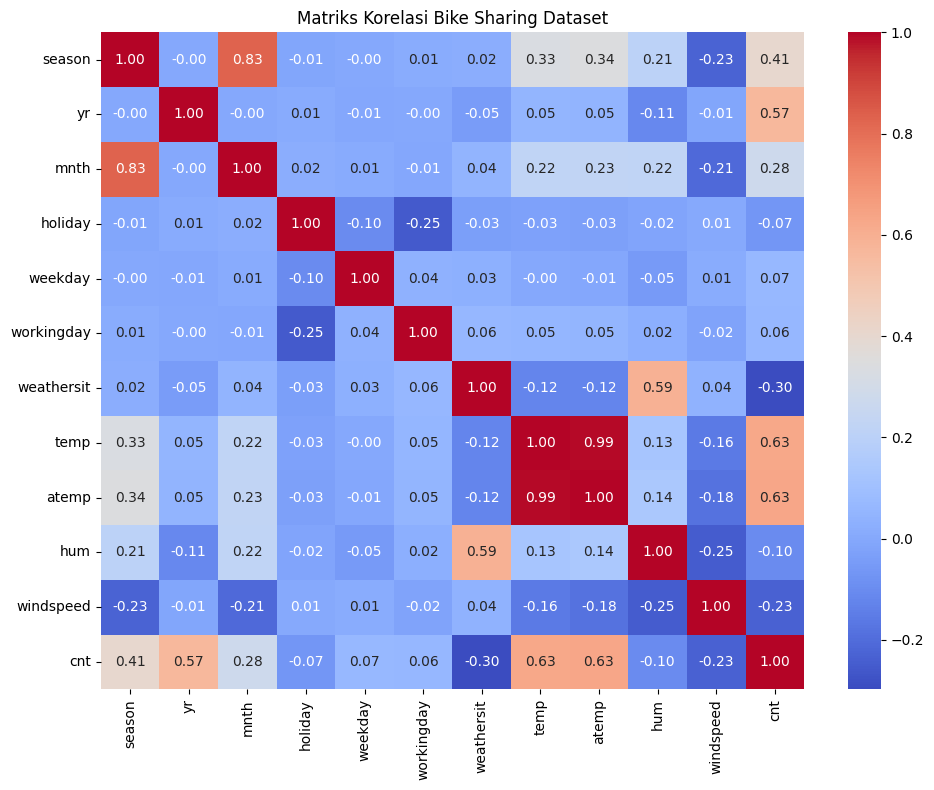

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Matriks korelasi
corr_matrix_bike = df_bike_clean.corr()

print("--- Korelasi Fitur Terhadap Target (cnt) ---")
print(corr_matrix_bike['cnt'].sort_values(ascending=False))

# Visualisasi Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_bike, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Bike Sharing Dataset')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Memilih fitur independen (X) dan target (y)
fitur_bike = ['temp', 'yr', 'hum', 'windspeed', 'season', 'weathersit']
X_bike = df_bike_clean[fitur_bike]
y_bike = df_bike_clean['cnt']

# Pembagian data 80:20
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bike, y_bike, test_size=0.2, random_state=42
)

print(f"Jumlah Data Latih (Train): {len(X_train_b)}")
print(f"Jumlah Data Uji (Test)  : {len(X_test_b)}")

Jumlah Data Latih (Train): 584
Jumlah Data Uji (Test)  : 147


In [ ]:
import statsmodels.api as sm

# Menambahkan konstanta
X_train_b_const = sm.add_constant(X_train_b)

# Latih model OLS
model_bike = sm.OLS(y_train_b, X_train_b_const).fit()

print("--- Parameter Koefisien Model OLS ---")
print(model_bike.params)

print("\n--- Summary Model OLS ---")
print(model_bike.summary())

--- Parameter Koefisien Model OLS ---
const         1747.449797
temp          5270.860337
yr            2009.036753
hum          -1041.418278
windspeed    -2307.096938
season         426.025912
weathersit    -591.518551
dtype: float64

--- Summary Model OLS ---
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.778
Model:                            OLS   Adj. R-squared:                  0.776
Method:                 Least Squares   F-statistic:                     337.5
Date:                Sun, 04 Oct 2026   Prob (F-statistic):          4.86e-185
Time:                        14:38:13   Log-Likelihood:                -4802.3
No. Observations:                 584   AIC:                             9619.
Df Residuals:                     577   BIC:                             9649.
Df Model:                           6                                         
Covariance Type:           

In [ ]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Prediksi pada data uji
X_test_b_const = sm.add_constant(X_test_b)
y_pred_b = model_bike.predict(X_test_b_const)

# Hitung metrik evaluasi
mse_b = mean_squared_error(y_test_b, y_pred_b)
r2_b = r2_score(y_test_b, y_pred_b)
mae_b = mean_absolute_error(y_test_b, y_pred_b)
rmse_b = np.sqrt(mse_b)

print("--- Metrik Evaluasi Data Uji ---")
print(f"R2   : {r2_b:.4f}")
print(f"MAE  : {mae_b:.2f}")
print(f"MSE  : {mse_b:.2f}")
print(f"RMSE : {rmse_b:.2f}")

--- Metrik Evaluasi Data Uji ---
R2   : 0.8187
MAE  : 639.29
MSE  : 727024.34
RMSE : 852.66


In [ ]:
# Membuat DataFrame perbandingan
hasil_bike = pd.DataFrame({
    'cnt Aktual': y_test_b.to_numpy(),
    'cnt Prediksi': y_pred_b.to_numpy()
})

# Hitung selisih error dan akurasi per baris
hasil_bike['Selisih error'] = hasil_bike['cnt Prediksi'] - hasil_bike['cnt Aktual']
denom_b = hasil_bike['cnt Aktual'].replace(0, np.nan)
hasil_bike['Akurasi (%)'] = (1 - (hasil_bike['Selisih error'].abs() / denom_b)).clip(0, 1) * 100

print("--- Tabel Hasil Prediksi (10 Baris Pertama) ---")
display(hasil_bike.head(10))

--- Tabel Hasil Prediksi (10 Baris Pertama) ---


,cnt Aktual,cnt Prediksi,Selisih error,Akurasi (%)
0,6606,6211.247789,-394.752211,94.024338
1,1550,1470.620606,-79.379394,94.878749
2,3747,2872.763388,-874.236612,76.668358
3,6041,4568.311763,-1472.688237,75.621781
4,7538,6629.220958,-908.779042,87.944030
5,7264,7210.870098,-53.129902,99.268586
6,1605,749.915037,-855.084963,46.723678
7,2209,2202.357860,-6.642140,99.699315
8,7499,7015.557600,-483.442400,93.553242
9,5743,6430.762731,687.762731,88.024330


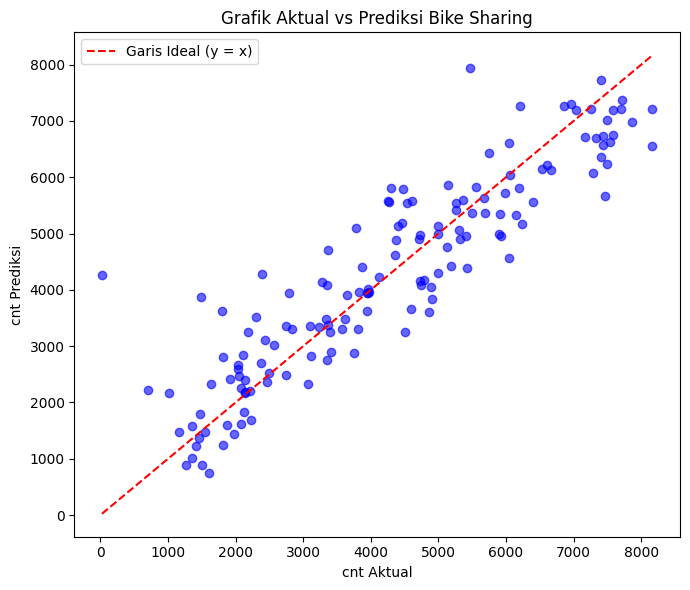

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_b, y_pred_b, alpha=0.6, color='blue')
lims = [min(y_test_b.min(), y_pred_b.min()), max(y_test_b.max(), y_pred_b.max())]
plt.plot(lims, lims, 'r--', label='Garis Ideal (y = x)')
plt.xlabel('cnt Aktual')
plt.ylabel('cnt Prediksi')
plt.title('Grafik Aktual vs Prediksi Bike Sharing')
plt.legend()
plt.tight_layout()
plt.show()